SPEECH EMOTION DETECTION PROJECT

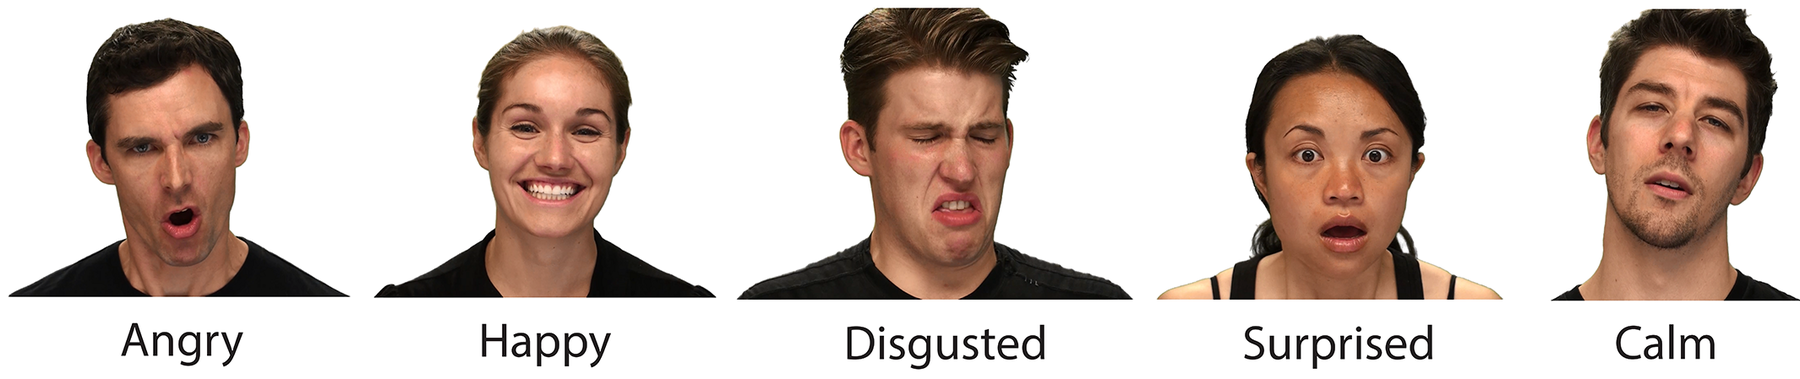

# Speech Emotion Recognition on RAVDESS

Classifying 8 emotions (neutral, calm, happy, sad, angry, fearful, disgust, surprised) from short speech clips, comparing three models:

1. **SVM** on summary MFCC statistics (baseline)
2. **MLP** on the same summary statistics
3. **1D-CNN** on the full MFCC time sequence

**Evaluation is speaker-independent.** Train, validation and test sets contain different actors, so the models are scored on voices they have never heard. This is harder than a random split, but it is the setting that reflects real use and avoids the speaker leakage that inflates many published RAVDESS results.

| Split | Actors | Purpose |
|---|---|---|
| Train | 1–18 | Fitting models and scalers |
| Validation | 19–20 | Hyperparameter choice and early stopping |
| Test | 21–24 | Final reported numbers, touched once |

Each split is gender-balanced (odd actor IDs are male, even are female).

## 1. Setup

In [3]:
!pip install librosa scikit-learn tensorflow kaggle seaborn -q

In [4]:
import os
import glob
import random
import zipfile
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import tensorflow as tf

import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('librosa', librosa.__version__, '| tensorflow', tf.__version__)

librosa 0.11.0 | tensorflow 2.21.0


## 2. Download the dataset

The [RAVDESS Kaggle mirror](https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio) is used. You need a Kaggle API token (`kaggle.json`, from *Kaggle → Settings → Create New Token*). **Never commit this file to GitHub**; it is listed in `.gitignore`.

In [5]:
DATA_DIR = 'ravdess_data'
KAGGLE_DATASET = 'uwrfkaggler/ravdess-emotional-speech-audio'

if not os.path.isdir(DATA_DIR):
    kaggle_cfg = os.path.expanduser('~/.kaggle/kaggle.json')
    if not os.path.exists(kaggle_cfg):
        # In Colab: upload kaggle.json interactively
        from google.colab import files
        files.upload()
        os.makedirs(os.path.dirname(kaggle_cfg), exist_ok=True)
        os.replace('kaggle.json', kaggle_cfg)
        os.chmod(kaggle_cfg, 0o600)

    subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_DATASET], check=True)
    with zipfile.ZipFile('ravdess-emotional-speech-audio.zip') as z:
        z.extractall(DATA_DIR)

print('Data directory ready:', DATA_DIR)

Saving kaggle.json to kaggle.json
Data directory ready: ravdess_data


## 3. Build the file index (and remove duplicates)

RAVDESS filenames encode all labels: `modality-vocal_channel-emotion-intensity-statement-repetition-actor.wav`.

**Important:** the Kaggle archive contains every actor folder twice (once at the top level and once inside `audio_speech_actors_01-24/`). Globbing recursively therefore finds 2,880 files instead of 1,440. If the copies are not removed, identical clips land in both train and test and the reported accuracy is inflated. Files are de-duplicated by name below.

In [6]:
EMOTIONS = {'01': 'neutral', '02': 'calm', '03': 'happy', '04': 'sad',
            '05': 'angry', '06': 'fearful', '07': 'disgust', '08': 'surprised'}

all_files = sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.wav'), recursive=True))
print(f'Files found by glob: {len(all_files)}')

records, seen = [], set()
for path in all_files:
    name = os.path.basename(path)
    if name in seen:
        continue  # duplicate copy of the same recording
    seen.add(name)
    modality, channel, emotion, intensity, statement, repetition, actor = name[:-4].split('-')
    if modality != '03' or channel != '01':
        continue  # keep audio-only speech
    records.append({
        'path': path,
        'emotion': EMOTIONS[emotion],
        'intensity': 'normal' if intensity == '01' else 'strong',
        'actor': int(actor),
        'gender': 'male' if int(actor) % 2 == 1 else 'female',
    })

df = pd.DataFrame(records)
print(f'Unique speech recordings: {len(df)}  (expected 1440)')
print(f'Actors: {df.actor.nunique()}')
df.head()

Files found by glob: 2880
Unique speech recordings: 1440  (expected 1440)
Actors: 24


,path,emotion,intensity,actor,gender
0,ravdess_data/Actor_01/03-01-01-01-01-01-01.wav,neutral,normal,1,male
1,ravdess_data/Actor_01/03-01-01-01-01-02-01.wav,neutral,normal,1,male
2,ravdess_data/Actor_01/03-01-01-01-02-01-01.wav,neutral,normal,1,male
3,ravdess_data/Actor_01/03-01-01-01-02-02-01.wav,neutral,normal,1,male
4,ravdess_data/Actor_01/03-01-02-01-01-01-01.wav,calm,normal,1,male


## 4. Exploratory data analysis

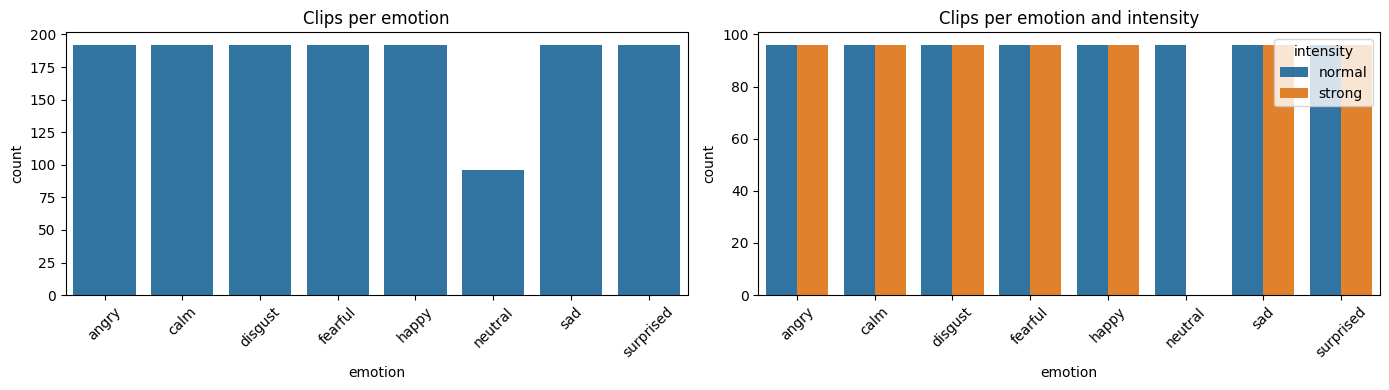

emotion
angry        192
calm         192
disgust      192
fearful      192
happy        192
neutral       96
sad          192
surprised    192
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = sorted(df.emotion.unique())
sns.countplot(data=df, x='emotion', order=order, ax=axes[0])
axes[0].set_title('Clips per emotion')
axes[0].tick_params(axis='x', rotation=45)
sns.countplot(data=df, x='emotion', hue='intensity', order=order, ax=axes[1])
axes[1].set_title('Clips per emotion and intensity')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print(df.emotion.value_counts().sort_index())

`neutral` has half as many clips as the other classes. This is by design: RAVDESS records neutral speech at normal intensity only. Because of this imbalance, **macro F1** is reported alongside accuracy, and the models use class weights.

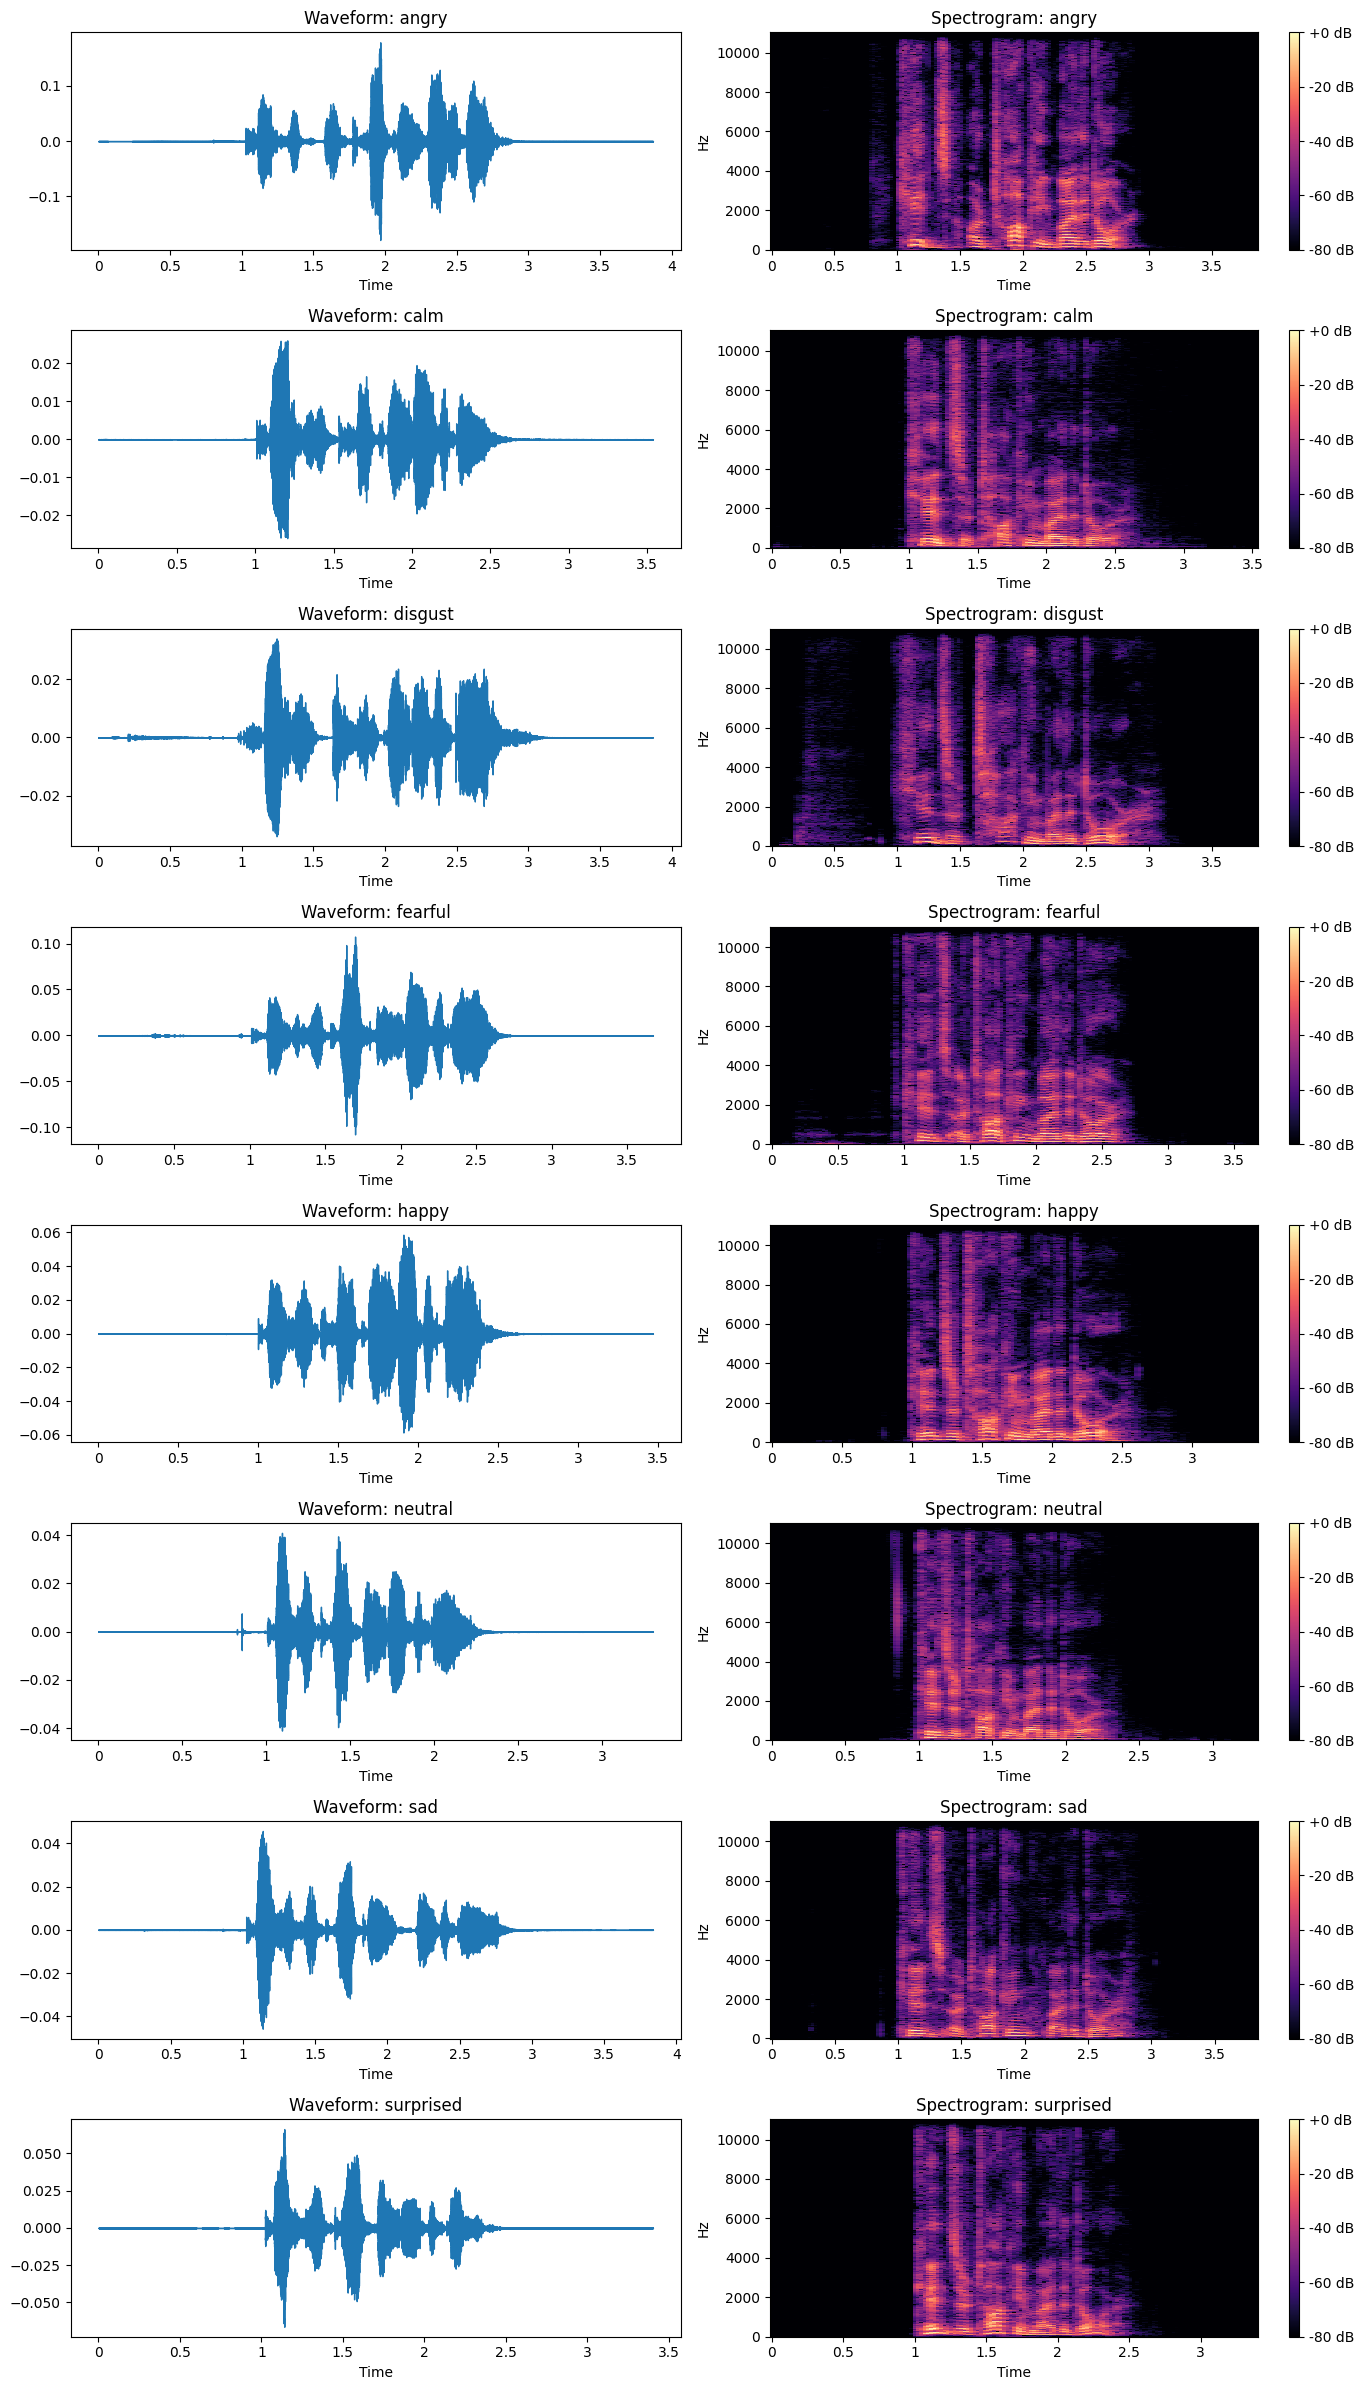

In [8]:
SR = 22050

fig, axes = plt.subplots(len(order), 2, figsize=(14, 3 * len(order)))
for i, emotion in enumerate(order):
    path = df[df.emotion == emotion].path.iloc[0]
    y, _ = librosa.load(path, sr=SR)
    librosa.display.waveshow(y, sr=SR, ax=axes[i, 0])
    axes[i, 0].set_title(f'Waveform: {emotion}')
    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(S_db, sr=SR, x_axis='time', y_axis='hz', ax=axes[i, 1])
    axes[i, 1].set_title(f'Spectrogram: {emotion}')
    fig.colorbar(img, ax=axes[i, 1], format='%+2.0f dB')
plt.tight_layout()
plt.show()

## 5. Feature extraction

Each clip is loaded at 22,050 Hz, skipping the first 0.5 s (RAVDESS clips start with silence) and cut or zero-padded to exactly 3 s. From it, two representations are computed:

- **Sequence features** for the CNN: the 40-coefficient MFCC matrix over time, shape `(frames, 40)`.
- **Summary features** for the SVM and MLP: the mean and standard deviation of each MFCC coefficient over time (80 values). Adding the standard deviation keeps some information about how the voice varies, which a mean alone loses.

In [9]:
DURATION = 3.0
OFFSET = 0.5
N_MFCC = 40
N_SAMPLES = int(SR * DURATION)

def extract_mfcc_sequence(path):
    y, _ = librosa.load(path, sr=SR, offset=OFFSET, duration=DURATION)
    y = librosa.util.fix_length(y, size=N_SAMPLES)
    return librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC).T  # (frames, n_mfcc)

sequences = np.stack([extract_mfcc_sequence(p) for p in df.path])
summary = np.concatenate([sequences.mean(axis=1), sequences.std(axis=1)], axis=1)

print('Sequence features:', sequences.shape)
print('Summary features: ', summary.shape)

Sequence features: (1440, 130, 40)
Summary features:  (1440, 80)


## 6. Speaker-independent split

In [10]:
TEST_ACTORS = [21, 22, 23, 24]
VAL_ACTORS = [19, 20]

test_mask = df.actor.isin(TEST_ACTORS).values
val_mask = df.actor.isin(VAL_ACTORS).values
train_mask = ~(test_mask | val_mask)

# Sanity checks: no speaker or file appears in more than one split
assert set(df.actor[train_mask]).isdisjoint(df.actor[test_mask])
assert set(df.actor[train_mask]).isdisjoint(df.actor[val_mask])
assert set(df.actor[val_mask]).isdisjoint(df.actor[test_mask])
assert df.path.map(os.path.basename).is_unique

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df.emotion)
CLASSES = label_encoder.classes_
N_CLASSES = len(CLASSES)

y_train, y_val, y_test = y_all[train_mask], y_all[val_mask], y_all[test_mask]

for name, mask in [('train', train_mask), ('val', val_mask), ('test', test_mask)]:
    actors = sorted(df.actor[mask].unique())
    print(f'{name:5s}: {mask.sum():4d} clips | actors {actors[0]}-{actors[-1]}')

train: 1080 clips | actors 1-18
val  :  120 clips | actors 19-20
test :  240 clips | actors 21-24


In [11]:
# Scalers are fitted on the training set only
scaler = StandardScaler().fit(summary[train_mask])
X_train = scaler.transform(summary[train_mask])
X_val = scaler.transform(summary[val_mask])
X_test = scaler.transform(summary[test_mask])

# Per-coefficient normalisation for the CNN, statistics from training data only
seq_mean = sequences[train_mask].mean(axis=(0, 1), keepdims=True)
seq_std = sequences[train_mask].std(axis=(0, 1), keepdims=True) + 1e-8
S_train = (sequences[train_mask] - seq_mean) / seq_std
S_val = (sequences[val_mask] - seq_mean) / seq_std
S_test = (sequences[test_mask] - seq_mean) / seq_std

weights = compute_class_weight('balanced', classes=np.arange(N_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))

## 7. Evaluation helper

In [12]:
results = {}

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    results[name] = {'accuracy': acc, 'macro_f1': macro_f1}

    print(f'{name}: accuracy = {acc:.3f} | macro F1 = {macro_f1:.3f}\n')
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

    cm = confusion_matrix(y_true, y_pred, normalize='true')
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, vmin=0, vmax=1)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'{name}: normalised confusion matrix (test set)')
    plt.tight_layout()
    plt.show()

## 8. Baseline: SVM

The regularisation strength `C` is chosen on the validation actors; the test set is not used for this choice.

C = 0.1   validation accuracy = 0.367
C = 1     validation accuracy = 0.483
C = 10    validation accuracy = 0.508
C = 100   validation accuracy = 0.500

Selected C = 10
SVM: accuracy = 0.425 | macro F1 = 0.423

              precision    recall  f1-score   support

       angry      0.346     0.562     0.429        32
        calm      0.571     0.375     0.453        32
     disgust      0.308     0.250     0.276        32
     fearful      0.556     0.469     0.508        32
       happy      0.200     0.219     0.209        32
     neutral      0.556     0.312     0.400        16
         sad      0.361     0.406     0.382        32
   surprised      0.706     0.750     0.727        32

    accuracy                          0.425       240
   macro avg      0.450     0.418     0.423       240
weighted avg      0.443     0.425     0.425       240



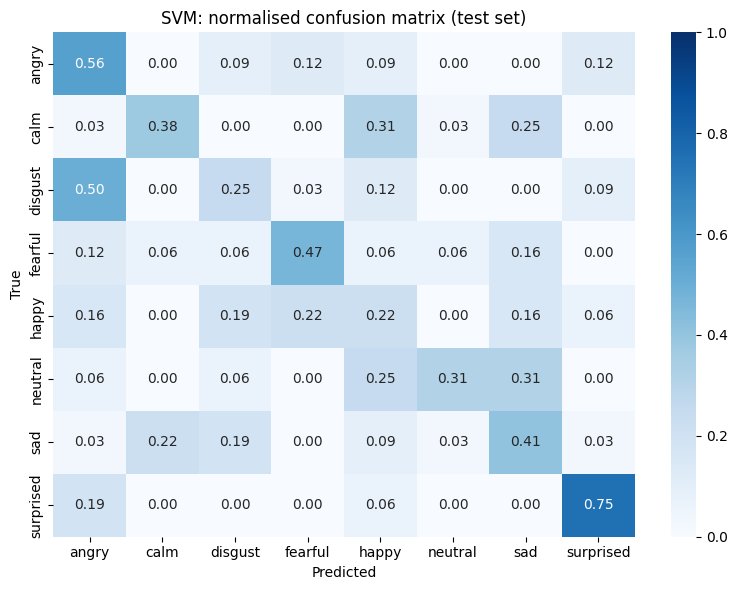

In [13]:
val_scores = {}
for C in [0.1, 1, 10, 100]:
    m = SVC(kernel='rbf', C=C, gamma='scale', class_weight='balanced', random_state=SEED)
    m.fit(X_train, y_train)
    val_scores[C] = accuracy_score(y_val, m.predict(X_val))
    print(f'C = {C:<5} validation accuracy = {val_scores[C]:.3f}')

best_C = max(val_scores, key=val_scores.get)
print(f'\nSelected C = {best_C}')

svm = SVC(kernel='rbf', C=best_C, gamma='scale', class_weight='balanced', random_state=SEED)
svm.fit(X_train, y_train)
evaluate('SVM', y_test, svm.predict(X_test))

## 9. MLP on summary features

A small fully connected network on the same 80 features as the SVM. Early stopping monitors the **validation** actors.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,200 (250.78 KB)

 Trainable params: 63,304 (247.28 KB)

 Non-trainable params: 896 (3.50 KB)

Trained for 27 epochs
MLP: accuracy = 0.467 | macro F1 = 0.454

              precision    recall  f1-score   support

       angry      0.655     0.594     0.623        32
        calm      0.714     0.312     0.435        32
     disgust      0.323     0.312     0.317        32
     fearful      0.381     0.500     0.432        32
       happy      0.298     0.438     0.354        32
     neutral      0.294     0.312     0.303        16
         sad      0.391     0.281     0.327        32
   surprised      0.784     0.906     0.841        32

    accuracy                          0.467       240
   macro avg      0.480     0.457     0.454       240
weighted avg      0.492     0.467     0.464       240



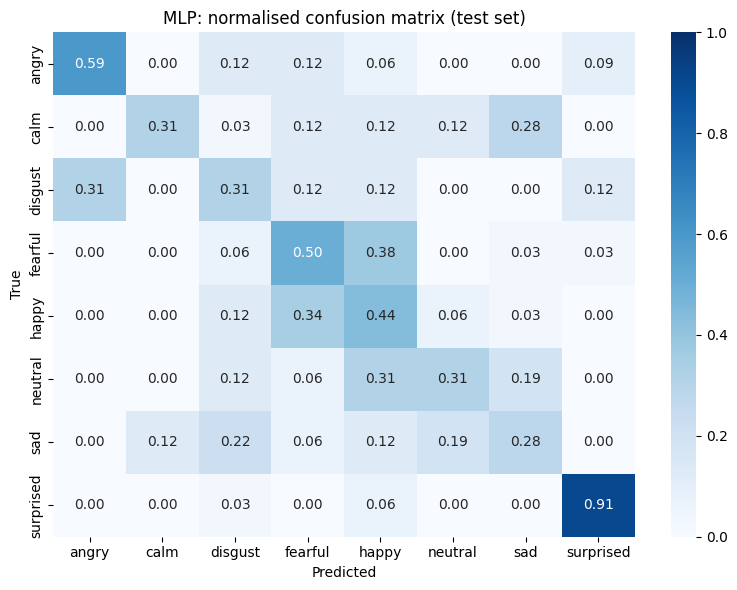

In [14]:
def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                         restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4),
    ]

mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(N_CLASSES, activation='softmax'),
])
mlp.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mlp.summary()

history_mlp = mlp.fit(X_train, y_train,
                      validation_data=(X_val, y_val),
                      epochs=150, batch_size=32,
                      class_weight=class_weight,
                      callbacks=make_callbacks(), verbose=0)
print(f'Trained for {len(history_mlp.history["loss"])} epochs')

evaluate('MLP', y_test, mlp.predict(X_test, verbose=0).argmax(axis=1))

## 10. 1D-CNN on MFCC sequences

Instead of collapsing each clip into averages, the CNN sees the MFCCs frame by frame and can learn short-term patterns such as pitch and energy changes. Convolutions run along the time axis; global average pooling makes the prediction independent of where in the clip the pattern occurs.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 130, 64)        │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 130, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 65, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 65, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 65, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 65, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 32, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 188,232 (735.28 KB)

 Trainable params: 187,336 (731.78 KB)

 Non-trainable params: 896 (3.50 KB)

Trained for 15 epochs
1D-CNN: accuracy = 0.400 | macro F1 = 0.376

              precision    recall  f1-score   support

       angry      0.452     0.594     0.514        32
        calm      1.000     0.219     0.359        32
     disgust      0.391     0.281     0.327        32
     fearful      0.714     0.156     0.256        32
       happy      0.214     0.375     0.273        32
     neutral      0.276     0.500     0.356        16
         sad      0.368     0.219     0.275        32
   surprised      0.509     0.906     0.652        32

    accuracy                          0.400       240
   macro avg      0.491     0.406     0.376       240
weighted avg      0.505     0.400     0.378       240



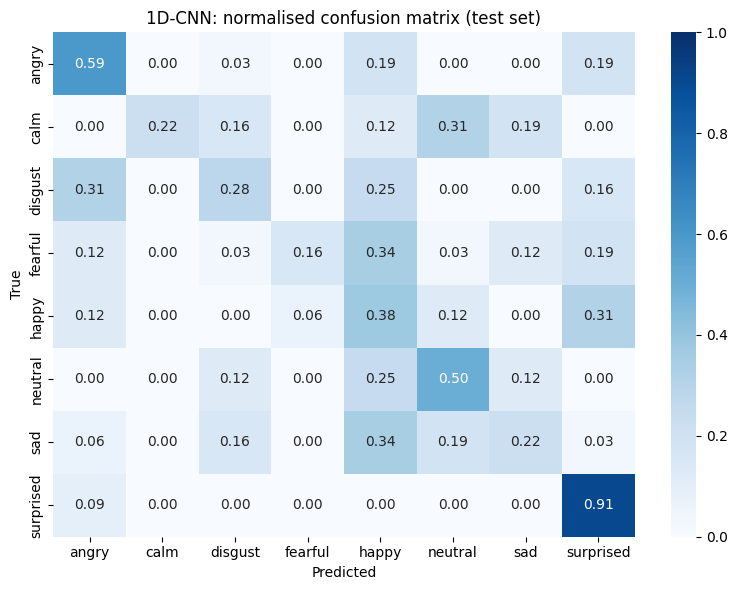

In [15]:
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=S_train.shape[1:]),
    tf.keras.layers.Conv1D(64, 5, padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling1D(2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv1D(128, 5, padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling1D(2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv1D(256, 3, padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(N_CLASSES, activation='softmax'),
])
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

history_cnn = cnn.fit(S_train, y_train,
                      validation_data=(S_val, y_val),
                      epochs=150, batch_size=32,
                      class_weight=class_weight,
                      callbacks=make_callbacks(), verbose=0)
print(f'Trained for {len(history_cnn.history["loss"])} epochs')

evaluate('1D-CNN', y_test, cnn.predict(S_test, verbose=0).argmax(axis=1))

## 11. Training curves

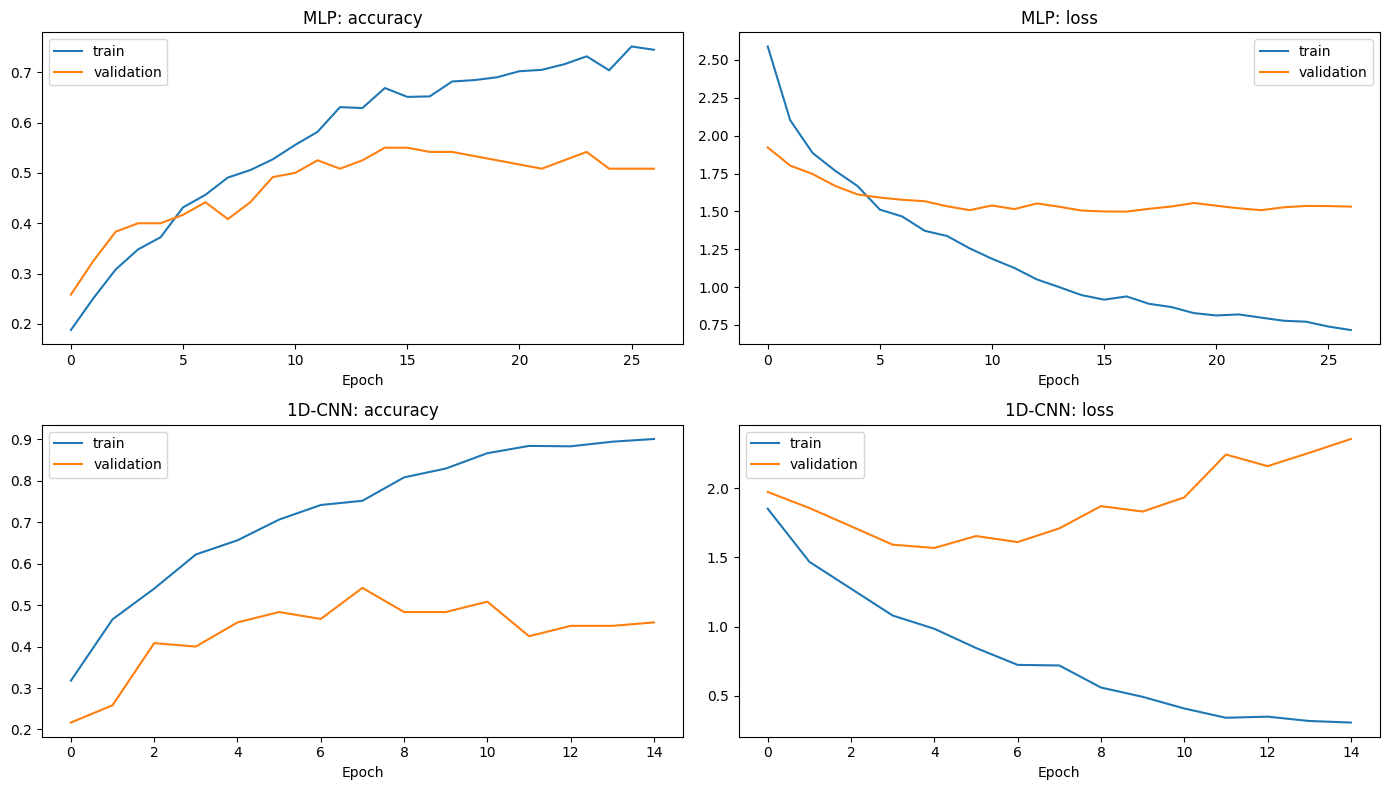

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, (name, hist) in enumerate([('MLP', history_mlp), ('1D-CNN', history_cnn)]):
    for col, metric in enumerate(['accuracy', 'loss']):
        ax = axes[row, col]
        ax.plot(hist.history[metric], label='train')
        ax.plot(hist.history[f'val_{metric}'], label='validation')
        ax.set_title(f'{name}: {metric}')
        ax.set_xlabel('Epoch')
        ax.legend()
plt.tight_layout()
plt.show()

## 12. Model comparison (test actors 21–24)

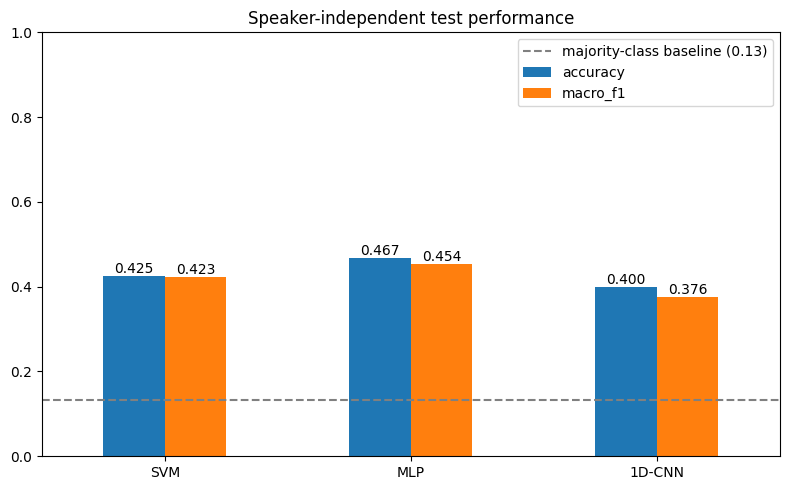

| Model | Accuracy | Macro F1 |
|---|---|---|
| SVM | 0.425 | 0.423 |
| MLP | 0.467 | 0.454 |
| 1D-CNN | 0.400 | 0.376 |


In [17]:
summary_df = pd.DataFrame(results).T
chance = df.emotion[test_mask].value_counts(normalize=True).max()

ax = summary_df.plot(kind='bar', figsize=(8, 5), rot=0, ylim=(0, 1))
ax.axhline(chance, color='grey', linestyle='--', label=f'majority-class baseline ({chance:.2f})')
ax.set_title('Speaker-independent test performance')
ax.legend()
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')
plt.tight_layout()
plt.show()

# Markdown table to paste into README.md
print('| Model | Accuracy | Macro F1 |')
print('|---|---|---|')
for name, row in summary_df.iterrows():
    print(f'| {name} | {row.accuracy:.3f} | {row.macro_f1:.3f} |')

## 13. Conclusions

On unseen speakers, all three models clearly beat the 13.3% majority-class baseline, reaching 40–47% accuracy. The MLP scored highest (46.7% accuracy, 0.454 macro F1), followed by the SVM (42.5%) and the 1D-CNN (40.0%). With only 240 test clips from 4 actors, the 95% confidence interval on each accuracy is roughly ±6 percentage points, so the gap between the MLP and the SVM is within noise.

**What gets confused.** The errors follow emotional *arousal* (energy level) rather than *valence* (positive vs negative):
- High-arousal emotions are mixed up with each other: fearful ↔ happy (38% and 34% of clips) and disgust → angry (31%).
- Low-arousal emotions are mixed up with each other: calm → sad (28%) and neutral → sad (19%).
- Surprised is by far the easiest class (91% recall for the MLP).

This makes sense: MFCC statistics capture loudness and spectral spread well, which separates calm from excited speech, but they carry little information about whether the emotion is pleasant or unpleasant.

**Why the CNN underperformed.** Its training curves show clear overfitting: training accuracy rises to about 90% while validation loss starts increasing after epoch 4. With only 18 training speakers, the model memorises speaker-specific detail instead of learning general emotion cues.

**Possible next steps**
- Data augmentation (noise, pitch shift, time stretch) to make up for the small number of speakers, especially for the CNN
- Prosodic features (pitch contour, energy, speaking rate) to help separate emotions with similar arousal
- Cross-validation over actor groups (`GroupKFold`) for more stable estimates than a single 4-actor test set
- Pretrained speech representations (e.g. wav2vec 2.0) as features